# A Hybrid Machine Learning Framework for Water Quality Index Prediction Using Adaptive Domain-Aware Neural Network Initialization

**Team (Batch 03, KITSW CSE — AI & ML):** Mohammed Nabi Adnan Ahmed (B23AI065), Sidda Samith (B23AI068), Sai Charith Chekurthi (B23AI087), Komandla Meghana (B23AI129)
**Supervisor:** Smt. K. Rama Devi

This notebook is the **complete project in one file**. Every line of code in the `src/` package is in here, in the same order, with the same values — run the cells top to bottom and you get the full experiment: data loading and verification, WAWQI, SHAP importance, the custom NumPy ANN (5 initialisations), the gated variant, baselines, 5-fold station-grouped cross-validation (75 ANN fits), and the station-level statistics.

## How to run it
- **In this repo:** open it from the `complete ipynb/` folder and Run All. It finds the data in `../data/` automatically.
- **On its own (e.g. Colab):** upload just this notebook and run it — the setup cell downloads the two data files from this GitHub repo. Install the dependencies first: `pip install -r requirements.txt` (numpy, pandas, scikit-learn, xgboost, shap, scipy, matplotlib).

## The honest story, in one paragraph
The target, WQI, is calculated from the same 7 water parameters fed to the network, using the Weighted Arithmetic formula — so WQI is a **linear function of the inputs**, and the ANN is reconstructing a known formula, not discovering a new relationship and not forecasting future water quality. The exact formula reproduces the target with ~0 error and Ridge gets MAE ≈ 0.3. The ANNs are in the thousands. That is the result, not a failure to hide: the contribution is the *study of initialisation and gating*, stated openly. Do not describe this project as forecasting, missing-parameter prediction, or a deployed system.

## What is NOT in here (say so in the viva)
- **No XGBoost late fusion / stacking.** "Hybrid" means XGBoost-informed initialisation (SHAP → ANN), not a late-fusion ensemble.
- **No SVR** in the final comparison (it is in the base paper, not in the final experiment).
- **No SHAP explanations of the trained ANN** — only XGBoost SHAP (before training) and learned gate values (after training).
- **No forecasting or deployment.** Station-grouped CV tests transfer to held-out stations, not to future years.

In [1]:
# Setup — run this cell first.
# Imports, data locations, and every constant the experiment needs
# (same values as src/config.py).
import json
import os
import time
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from scipy import stats
from sklearn.ensemble import (
    ExtraTreesRegressor,
    HistGradientBoostingRegressor,
    RandomForestRegressor,
)
from sklearn.linear_model import Ridge
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor

# --- Where is the data? ---------------------------------------------------
# This notebook lives in <project>/complete ipynb/, so the project root is
# its parent directory. If you run the notebook on its own (e.g. Colab),
# the two data files are downloaded from this repo instead.
REPO_RAW = "https://raw.githubusercontent.com/NabiAdnan/wqi-major-project/main"


def _find_project_root():
    here = Path.cwd()
    for parent in [here, *here.parents]:
        if (parent / "data" / "processed" / "water_quality_1572_audited_recomputed.csv").exists():
            return parent
    return None


PROJECT_ROOT = _find_project_root()
if PROJECT_ROOT is None:
    PROJECT_ROOT = Path.cwd() / "wqi-major-project"
    (PROJECT_ROOT / "data" / "raw").mkdir(parents=True, exist_ok=True)
    (PROJECT_ROOT / "data" / "processed").mkdir(parents=True, exist_ok=True)
    for rel in ("data/raw/water_dataX.csv",
                "data/processed/water_quality_1572_audited_recomputed.csv"):
        dest = PROJECT_ROOT / rel
        if not dest.exists():
            print(f"Downloading {rel} ...")
            urllib.request.urlretrieve(f"{REPO_RAW}/{rel}", dest)
    print("Data downloaded from the GitHub repo.")

RAW_DATA_PATH = PROJECT_ROOT / "data" / "raw" / "water_dataX.csv"
AUDITED_DATA_PATH = (
    PROJECT_ROOT / "data" / "processed"
    / "water_quality_1572_audited_recomputed.csv"
)
OUTPUT_DIR = PROJECT_ROOT / "outputs"

# --- The seven model features, in the order used everywhere ---------------
FEATURES = [
    "do",
    "ph",
    "conductivity",
    "bod",
    "nitrate",
    "fecal_coliform",
    "total_coliform",
]

# --- Weighted Arithmetic WQI constants ------------------------------------
# q_i = 100 * (V_i - ideal_i) / (Std_i - ideal_i)
# D_i = (1 / Std_i) / sum_j (1 / Std_j);  WQI = sum_i D_i * q_i
STANDARDS = {
    "do": 10.0,
    "ph": 8.5,
    "conductivity": 1000.0,
    "bod": 5.0,
    "nitrate": 45.0,
    "fecal_coliform": 100.0,
    "total_coliform": 1000.0,
}
IDEALS = {
    "do": 14.6,
    "ph": 7.0,
    "conductivity": 0.0,
    "bod": 0.0,
    "nitrate": 0.0,
    "fecal_coliform": 0.0,
    "total_coliform": 0.0,
}

# --- Adaptive importance: A_i = 0.8 * S_i + 0.2 * D_i (beta = 0.2 frozen) --
BETA = 0.2

# --- ANN ------------------------------------------------------------------
HIDDEN_1 = 16
HIDDEN_2 = 8
LEARNING_RATE = 0.001
ADAM_BETA1 = 0.9
ADAM_BETA2 = 0.999
ADAM_EPS = 1e-8
MAX_EPOCHS = 1800
EARLY_STOPPING_PATIENCE = 140
SEEDS = (17, 41, 73)

# --- Cross-validation / XGBoost / stats -----------------------------------
N_FOLDS = 5
VALIDATION_GROUP_FRACTION = 0.15
VALIDATION_SPLIT_SEED = 42
XGBOOST_PARAMS = {
    "n_estimators": 100,
    "max_depth": 5,
    "learning_rate": 0.1,
    "random_state": 42,
    "n_jobs": -1,
}
BOOTSTRAP_RESAMPLES = 5000
BOOTSTRAP_SEED = 42

# --- Expected data audit (the loader fails loudly if these do not match) --
EXPECTED_RAW_ROWS = 1991
EXPECTED_AFTER_DEDUP = 1990
EXPECTED_CLEAN_ROWS = 1572
EXPECTED_N_GROUPS = 356
EXPECTED_CODE_ROWS = 1479
EXPECTED_LOC_ROWS = 93
EXPECTED_QC_FLAGS = {
    "fecal_coliform_gt_100": 1008,
    "fecal_coliform_gt_1M": 3,
    "total_coliform_gt_1M": 3,
    "conductivity_gt_10000": 103,
    "bod_gt_100": 7,
    "do_eq_0": 1,
    "ph_outside_6.5_8.5": 116,
}

print("Project root:", PROJECT_ROOT)
print("Audited data:", AUDITED_DATA_PATH)
print("Raw data:", RAW_DATA_PATH)


/home/hatch/workspace/projects/payguard-ai/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Project root: /home/hatch/workspace/projects/wqi-major-project
Audited data: /home/hatch/workspace/projects/wqi-major-project/data/processed/water_quality_1572_audited_recomputed.csv
Raw data: /home/hatch/workspace/projects/wqi-major-project/data/raw/water_dataX.csv


## 1. The WQI formula — Weighted Arithmetic WQI (WAWQI)

$q_i = 100 \cdot (V_i - ideal_i) / (Std_i - ideal_i)$, $D_i = (1/Std_i) / \sum_j (1/Std_j)$, $WQI = \sum_i D_i q_i$.

Standards / ideals: DO 10 / 14.6, pH 8.5 / 7.0, conductivity 1000 / 0, BOD 5 / 0, nitrate 45 / 0, fecal coliform 100 / 0, total coliform 1000 / 0. That gives D = DO 0.2213, pH 0.2604, conductivity 0.0022, BOD 0.4426, nitrate 0.0492, fecal 0.0221, total 0.0022.

Two things to understand: (1) the standards, ideals and weights are fixed, so WQI is a linear function of the 7 inputs — the exact formula below is the honest baseline every model is judged against; (2) the pH sub-index is one-sided (ideal 7, standard 8.5), so pH < 7 gives a negative sub-index — that is why the dataset has 3 negative WQI values, kept as specified.

In [2]:
"""Weighted Arithmetic Water Quality Index (WAWQI).

This module contains only the WQI formula. It knows nothing about
files, models, or cross-validation, so it can be tested on its own.

Formula (for each of the 7 parameters):
    q_i  = 100 * (V_i - ideal_i) / (Std_i - ideal_i)   (quality rating)
    D_i  = (1 / Std_i) / sum_j (1 / Std_j)             (domain relevance)
    WQI  = sum_i D_i * q_i

Two things to understand before using it:
1. The standards, ideals and weights are fixed, so WQI is a *linear*
   function of the 7 inputs. The ANN in this project is therefore
   learning to reconstruct a known formula, not discovering a new
   relationship. The exact formula (``exact_wqi`` below) reproduces
   the target with ~0 error, and Ridge regression gets very close.
   That is the honest baseline every other method is judged against.
2. The pH sub-index is one-sided: ideal pH is 7.0, standard is 8.5,
   so a pH below 7 gives a *negative* q_i. That is why the cleaned
   dataset contains 3 negative WQI values. We keep the formula as
   specified; a two-sided pH version is a sensitivity variant only
   and must not be silently substituted for this one.
"""



# STANDARDS / IDEALS are dicts in config; the arrays below are built
# in FEATURES order so index i always means feature i.


def domain_relevance():
    """Return D_i for the 7 features, in FEATURES order.

    D_i = (1 / Std_i) / sum_j (1 / Std_j).  Sums to 1 by construction.
    BOD gets the largest weight (0.4426) because its standard is the
    smallest (5); conductivity and total coliform get the smallest
    (0.0022 each) because their standards are the largest (1000).
    """
    standards = np.array([STANDARDS[f] for f in FEATURES], dtype=float)
    reciprocal = 1.0 / standards
    return reciprocal / reciprocal.sum()


def quality_ratings(values):
    """Return the sub-index q_i for each feature.

    ``values`` is an array of shape (..., 7) in FEATURES order, or a
    single row of shape (7,). The return has the same shape.
    """
    values = np.asarray(values, dtype=float)
    standards = np.array([STANDARDS[f] for f in FEATURES], dtype=float)
    ideals = np.array([IDEALS[f] for f in FEATURES], dtype=float)
    return 100.0 * (values - ideals) / (standards - ideals)


def exact_wqi(values):
    """Compute WQI directly from the 7 raw measurements.

    ``values`` is an array of shape (n, 7) or (7,) in FEATURES order.
    Returns the WQI for each row. This is the mathematical reference:
    it is not a model, and it is expected to reproduce the target
    with (numerically) zero error.
    """
    values = np.asarray(values, dtype=float)
    single_row = values.ndim == 1
    if single_row:
        values = values.reshape(1, -1)
    wqi = quality_ratings(values) @ domain_relevance()
    return float(wqi[0]) if single_row else wqi


## 2. Data — the audited file is the primary input

Primary: `data/processed/water_quality_1572_audited_recomputed.csv` — the team's audited file, 1,572 rows × 47 columns, 356 station groups (CODE: 1,479, LOC: 93), years 2005–2014. `load_audited()` **verifies** it instead of trusting it: it recomputes WQI from the 7 raw features and fails loudly unless the max difference is < 1e-3 (in practice ~1e-9), there are 1,572 rows and 356 groups. Only the primary `WQI` column is used — never the two-sided-pH or asinh sensitivity columns.

Source of truth: `data/raw/water_dataX.csv` — Kaggle, anbarivan/indian-water-quality-data, 1,991 rows. `clean()` reproduces the 1,572 rows: drop exact duplicates (1991 → 1990), drop rows missing any of the 7 features (→ 1625), drop pH outside [0, 14] (→ 1572). The 53 dropped rows are all 2003–2004 with impossible pH (e.g. 239, 1148) and pH-like conductivity — they look swapped in the source, but they are dropped, not repaired. `cross_check_raw_vs_audited()` checks the two files agree.

In [3]:
"""Load and clean the Indian Water Quality dataset.

Two input files, two jobs — do not confuse them:

PRIMARY INPUT (used by run_experiment.py):
    data/processed/water_quality_1572_audited_recomputed.csv
    The team's audited, prepared file: 1,572 rows, 47 columns.
    ``load_audited()`` reads it, renames ``nitrate_nitrite`` to the
    internal name ``nitrate``, takes the 7 raw features plus
    ``station_group_id``, and uses the ``WQI`` column as the target.
    It then VERIFIES the file instead of trusting it: it recomputes
    WQI from the 7 raw features with the WAWQI formula and fails
    loudly unless the maximum difference is < 1e-3, there are 1,572
    rows, and there are 356 station groups.

    Columns you must NOT use as the target:
      * ``WQI_two_sided_pH_sensitivity`` — a sensitivity variant in
        which pH is treated two-sidedly. Not the primary formula.
      * ``WQI_asinh_scale100``, ``WQI_original_asinh_scale100``,
        ``WQI_two_sided_pH_asinh_scale100`` — asinh-transformed
        versions, also sensitivity variants only.
      * ``log1p_*`` — log-transformed features, also sensitivity
        variants only, not used in the primary experiment.
    Temperature has 46 nulls in this file; it is irrelevant because
    temperature is not one of the 7 model features.

SOURCE OF TRUTH (kept, and cross-checked):
    data/raw/water_dataX.csv
    The original Kaggle file (anbarivan/indian-water-quality-data,
    https://www.kaggle.com/datasets/anbarivan/indian-water-quality-data).
    The copy in this repo was re-encoded from the Kaggle download's
    latin-1 to UTF-8 (same characters, including the micro sign in
    the conductivity header) so it can be stored on GitHub, which
    requires UTF-8 text. ``load_raw()`` accepts both encodings, so
    a fresh latin-1 download from Kaggle still loads. ``clean()``
    reproduces the 1,572 rows from it, and
    ``cross_check_raw_vs_audited()`` checks the two files agree on
    counts, groups, QC flags, and WQI summary statistics.
    Exact row-by-row joining is NOT done by sample_id: the audited
    file's sample_id (INDWQ_00001, ...) does not exist in the raw
    file. The cross-check therefore compares aggregates, and also
    joins on station + location + year + the 7 features where a
    row-level check is wanted (see the tests).

Cleaning pipeline for the raw file (in order):
    1. Read the CSV (UTF-8 in this repo; a fresh Kaggle download is
       latin-1 — ``load_raw()`` accepts both, because the
       conductivity column header contains a micro sign).
    2. Drop exact duplicate rows: 1991 -> 1990.
    3. Convert the 7 feature columns to numeric (anything that does
       not parse becomes NaN).
    4. Drop rows with a missing / non-finite value in any of the
       7 features: 1990 -> 1625.
    5. Drop rows with a negative value in any feature (a negative
       concentration is physically impossible). In this file there
       are none, so the count stays 1625 — the step is kept because
       it is part of the documented procedure, not because it bites.
    6. Drop rows with pH outside [0, 14]: 1625 -> 1572.

Step 6 needs a clear explanation, because it drops 53 rows:
    pH is physically defined on 0-14. The 53 dropped rows all have
    pH values like 239, 86, 101, 1148, 9416 — while their conductivity
    is a plausible pH-like number (6.2, 7.8, ...). All 53 are from
    2003-2004, i.e. before the 2005-2014 window of the kept data.
    It looks as if pH and conductivity were swapped in the source
    file for those rows, but we do NOT swap them back: that would be
    guessing at the data. We drop them as a data-quality filter and
    document it here and in the README.

What we do NOT do: we do not remove extreme values just because
they are large. A fecal coliform of >1,000,000 may be genuine
contamination, and removing polluted samples without justification
would bias the dataset. Extreme values are flagged (see
``qc_flags``), not deleted.

Station groups:
    station_group_id = "CODE:<station code>" if the station code is
    present, else "LOC:<location>". In the raw file the code column
    stores the string 'NAN' for a missing code. Result: 356 groups,
    1479 CODE: rows, 93 LOC: rows. "356 groups" means 356 distinct
    grouping IDs, not 356 independently verified physical sampling
    stations.
"""



# Raw column names, matched by prefix so the micro sign in the
# conductivity header cannot break the load on a different encoding.
_RAW_COLUMN_PREFIXES = {
    "do": "D.O.",
    "ph": "PH",
    "conductivity": "CONDUCTIVITY",
    "bod": "B.O.D.",
    "nitrate": "NITRATENAN",
    "fecal_coliform": "FECAL COLIFORM",
    "total_coliform": "TOTAL COLIFORM",
}

# Column name in the audited file -> internal feature name.
# Only nitrate differs (audited: nitrate_nitrite).
_AUDITED_FEATURE_COLUMNS = {
    "do": "do",
    "ph": "ph",
    "conductivity": "conductivity",
    "bod": "bod",
    "nitrate": "nitrate_nitrite",
    "fecal_coliform": "fecal_coliform",
    "total_coliform": "total_coliform",
}

# How close the recomputed WQI must be to the audited file's WQI
# column. In practice the difference is ~1e-9 (floating-point
# rounding); 1e-3 is a generous tolerance that still catches a wrong
# formula, a wrong column, or a swapped standard.
WQI_VERIFICATION_TOLERANCE = 1e-3


def _find_raw_column(columns, prefix):
    """Return the one column whose name starts with ``prefix``."""
    matches = [c for c in columns if str(c).startswith(prefix)]
    if len(matches) != 1:
        raise ValueError(
            f"Expected exactly one column starting with {prefix!r}, "
            f"found {matches!r}"
        )
    return matches[0]


# ------------------------------------------------------------ audited file
def load_audited(path=AUDITED_DATA_PATH, verify=True):
    """Load the team's audited 1,572-row file (the primary input).

    Returns a dataframe with the 7 features (internal names, in
    FEATURES order), ``station_group_id``, ``year``, ``sample_id``,
    and ``wqi`` (the file's primary ``WQI`` column).

    If ``verify`` is True (the default), the file is checked before
    it is used: 1,572 rows, 356 groups, and the WQI column must
    match a fresh recomputation from the 7 raw features to within
    1e-3. A mismatch raises ValueError instead of silently training
    on a wrong target.
    """
    df = pd.read_csv(path)
    if len(df) != EXPECTED_CLEAN_ROWS:
        raise ValueError(
            f"Audited file has {len(df)} rows, expected "
            f"{EXPECTED_CLEAN_ROWS}"
        )
    if "WQI" not in df.columns:
        raise ValueError("Audited file has no 'WQI' column")
    if "station_group_id" not in df.columns:
        raise ValueError("Audited file has no 'station_group_id' column")

    out = pd.DataFrame()
    for feature in FEATURES:
        out[feature] = pd.to_numeric(
            df[_AUDITED_FEATURE_COLUMNS[feature]], errors="coerce"
        )
    out["station_group_id"] = df["station_group_id"].astype(str)
    out["year"] = pd.to_numeric(df["year"], errors="coerce")
    out["sample_id"] = df["sample_id"].astype(str)
    # PRIMARY target only. Two-sided-pH and asinh columns are
    # sensitivity variants and are deliberately never read here.
    out["wqi"] = pd.to_numeric(df["WQI"], errors="coerce")

    if out[FEATURES + ["wqi"]].isna().any().any():
        raise ValueError(
            "Audited file has missing values in the 7 features or WQI"
        )

    if verify:
        verify_audited(out, df)

    return out.reset_index(drop=True)


def verify_audited(cleaned, raw_audited=None):
    """Check the audited file's WQI column against the WAWQI formula.

    Recomputes WQI from the 7 raw features and compares it with the
    file's ``WQI`` column. Also checks the group count and, when the
    original audited frame is supplied, that the 7 q_i columns in
    the file match the formula's sub-indices exactly.
    Raises ValueError on any mismatch. Returns the max |difference|.
    """
    recomputed = exact_wqi(cleaned[FEATURES].to_numpy(dtype=float))
    max_diff = float(
        np.max(np.abs(recomputed - cleaned["wqi"].to_numpy(dtype=float)))
    )
    if max_diff >= WQI_VERIFICATION_TOLERANCE:
        raise ValueError(
            f"Audited WQI does not match recomputation: "
            f"max |difference| = {max_diff}, "
            f"tolerance = {WQI_VERIFICATION_TOLERANCE}"
        )
    n_groups = int(cleaned["station_group_id"].nunique())
    if n_groups != EXPECTED_N_GROUPS:
        raise ValueError(
            f"Audited file has {n_groups} station groups, "
            f"expected {EXPECTED_N_GROUPS}"
        )
    if raw_audited is not None and "qc_formula_match_original_WQI" in raw_audited:
        if not bool(raw_audited["qc_formula_match_original_WQI"].all()):
            raise ValueError(
                "Audited file's qc_formula_match_original_WQI is "
                "False for some rows"
            )
    return max_diff


# --------------------------------------------------------------- raw file
def load_raw(path=RAW_DATA_PATH):
    """Read the raw Kaggle CSV and return it unchanged (except header).

    The copy in this repo is UTF-8; a fresh download from Kaggle is
    latin-1. Try UTF-8 first and fall back to latin-1, so both load.
    """
    try:
        return pd.read_csv(path, encoding="utf-8", keep_default_na=False)
    except UnicodeDecodeError:
        return pd.read_csv(path, encoding="latin-1", keep_default_na=False)


def clean(df):
    """Apply the cleaning pipeline to the raw frame; see module docstring.

    Returns a frame with the 7 features as float columns named after
    FEATURES, plus ``station_group_id``, ``year``, and ``wqi``
    (recomputed from the 7 raw inputs with the WAWQI formula).
    """
    df = df.drop_duplicates().copy()

    # 7 feature columns, converted to numeric.
    for feature in FEATURES:
        raw_col = _find_raw_column(df.columns, _RAW_COLUMN_PREFIXES[feature])
        df[feature] = pd.to_numeric(df[raw_col], errors="coerce")

    # Drop rows missing any required input.
    df = df.dropna(subset=FEATURES)

    # Drop physically impossible negative measurements (none in this
    # file, but the check is part of the documented procedure).
    df = df[(df[FEATURES] >= 0).all(axis=1)]

    # Data-quality filter: pH must lie in [0, 14]. See the module
    # docstring for why these 53 rows are dropped, not repaired.
    df = df[(df["ph"] >= 0) & (df["ph"] <= 14)]

    # Station group: CODE:<code>, or LOC:<location> if code is 'NAN'.
    code = df["STATION CODE"].astype(str).str.strip()
    location = df["LOCATIONS"].astype(str).str.strip()
    df["station_group_id"] = np.where(
        code != "NAN", "CODE:" + code, "LOC:" + location
    )

    # Drop rows whose group identifier is missing/empty. (None in
    # this file; kept so a future data version fails loudly, not
    # silently, if a group cannot be formed.)
    df = df[df["station_group_id"].str.strip() != ""]
    df = df[~df["station_group_id"].isin(["CODE:", "LOC:"])]

    # Target: recompute WQI from the 7 raw inputs, every time.
    # We never trust a precomputed WQI column from the file.
    df["wqi"] = exact_wqi(df[FEATURES].to_numpy(dtype=float))

    df["year"] = pd.to_numeric(df["year"], errors="coerce")
    return df.reset_index(drop=True)


def load_cleaned(path=RAW_DATA_PATH):
    """Load the raw file and return the cleaned analysis dataframe."""
    return clean(load_raw(path))


# ------------------------------------------------------------- QC + audit
def qc_flags(df):
    """Count the quality-control flags on a cleaned dataframe.

    Flags overlap (one row can be flagged several times), so the
    counts must NOT be added together. These are the values the
    unit tests check against the technical document.
    """
    return {
        "fecal_coliform_gt_100": int((df["fecal_coliform"] > 100).sum()),
        "fecal_coliform_gt_1M": int((df["fecal_coliform"] > 1_000_000).sum()),
        "total_coliform_gt_1M": int((df["total_coliform"] > 1_000_000).sum()),
        "conductivity_gt_10000": int((df["conductivity"] > 10000).sum()),
        "bod_gt_100": int((df["bod"] > 100).sum()),
        "do_eq_0": int((df["do"] == 0).sum()),
        "ph_outside_6.5_8.5": int(
            ((df["ph"] < 6.5) | (df["ph"] > 8.5)).sum()
        ),
    }


def audit(df):
    """Return a dict summarising a cleaned dataset (for the report)."""
    return {
        "n_rows": int(len(df)),
        "n_groups": int(df["station_group_id"].nunique()),
        "n_code_rows": int(
            df["station_group_id"].str.startswith("CODE:").sum()
        ),
        "n_loc_rows": int(
            df["station_group_id"].str.startswith("LOC:").sum()
        ),
        "year_min": int(df["year"].min()),
        "year_max": int(df["year"].max()),
        "wqi_min": float(df["wqi"].min()),
        "wqi_max": float(df["wqi"].max()),
        "wqi_median": float(df["wqi"].median()),
        "wqi_negative": int((df["wqi"] < 0).sum()),
        "qc_flags": qc_flags(df),
        "qc_flags_expected": dict(EXPECTED_QC_FLAGS),
    }


def _normalise_group_id(group_id):
    """Normalise a station_group_id for cross-file comparison.

    The audited file's LOC fallback IDs differ textually from the
    raw file's in two small ways, although they denote the same
    groups:
      * audited appends "|STATE:NAN" to LOC ids
        (e.g. "LOC:...|STATE:NAN" vs raw "LOC:...");
      * audited collapses double spaces in 3 location strings
        ("KAKKADAVU,  KERALA" -> "KAKKADAVU, KERALA", and two
        similar cases).
    Stripping the "|STATE:..." suffix and collapsing whitespace
    makes the two group label sets identical, and the per-group
    row counts are then equal for all 356 groups — i.e. the
    grouping *partition* is the same, only the labels differ.
    (CODE: ids are identical in both files.)
    """
    import re

    text = re.sub(r"\|STATE:.*$", "", str(group_id))
    return re.sub(r"\s+", " ", text).strip()


def cross_check_raw_vs_audited(raw_cleaned, audited):
    """Compare the raw-cleaned frame with the audited file.

    Exact row-by-row joining on sample_id is impossible: the
    audited file's sample_id (INDWQ_00001, ...) does not exist in
    the raw file. So this compares:
      * aggregates — row count, group count, QC flags, and WQI
        min/max/median;
      * the grouping partition — group label sets and per-group
        row counts, after normalising the LOC label differences
        described in ``_normalise_group_id``;
      * the row multiset — both frames sorted by year + the 7
        features + WQI must match row for row. A join on
        group+year+features is NOT used: two rows can share the
        same 7 features and year while belonging to different
        stations, so that join is not 1:1.

    Returns a dict with the comparison. Raises ValueError if any
    check disagrees beyond tolerance.
    """
    checks = {
        "n_rows_raw": int(len(raw_cleaned)),
        "n_rows_audited": int(len(audited)),
        "n_groups_raw": int(raw_cleaned["station_group_id"].nunique()),
        "n_groups_audited": int(audited["station_group_id"].nunique()),
        "qc_flags_raw": qc_flags(raw_cleaned),
        "qc_flags_audited": qc_flags(audited),
        "wqi_min_raw": float(raw_cleaned["wqi"].min()),
        "wqi_min_audited": float(audited["wqi"].min()),
        "wqi_max_raw": float(raw_cleaned["wqi"].max()),
        "wqi_max_audited": float(audited["wqi"].max()),
        "wqi_median_raw": float(raw_cleaned["wqi"].median()),
        "wqi_median_audited": float(audited["wqi"].median()),
    }
    if checks["n_rows_raw"] != checks["n_rows_audited"]:
        raise ValueError(
            f"Row count mismatch: raw-cleaned {checks['n_rows_raw']} "
            f"vs audited {checks['n_rows_audited']}"
        )
    if checks["n_groups_raw"] != checks["n_groups_audited"]:
        raise ValueError(
            f"Group count mismatch: raw-cleaned {checks['n_groups_raw']} "
            f"vs audited {checks['n_groups_audited']}"
        )
    if checks["qc_flags_raw"] != checks["qc_flags_audited"]:
        raise ValueError(
            f"QC flag mismatch: raw {checks['qc_flags_raw']} "
            f"vs audited {checks['qc_flags_audited']}"
        )
    for key in ("wqi_min", "wqi_max", "wqi_median"):
        raw_val = checks[key + "_raw"]
        aud_val = checks[key + "_audited"]
        if abs(raw_val - aud_val) > 1e-6 * max(1.0, abs(aud_val)):
            raise ValueError(
                f"{key} mismatch: raw {raw_val} vs audited {aud_val}"
            )
    # Grouping partition: same groups, same per-group row counts,
    # after normalising the LOC label differences.
    raw_groups = raw_cleaned["station_group_id"].map(_normalise_group_id)
    aud_groups = audited["station_group_id"].map(_normalise_group_id)
    if set(raw_groups) != set(aud_groups):
        raise ValueError(
            "Station group sets differ after normalising LOC labels: "
            f"only in raw {sorted(set(raw_groups) - set(aud_groups))[:5]}, "
            f"only in audited {sorted(set(aud_groups) - set(raw_groups))[:5]}"
        )
    raw_counts = raw_groups.value_counts().sort_index()
    aud_counts = aud_groups.value_counts().sort_index()
    if not raw_counts.equals(aud_counts):
        raise ValueError("Per-group row counts differ between raw and audited")
    checks["n_groups_normalised"] = int(len(set(raw_groups)))

    # Row multiset: sort both frames by year + 7 features + WQI and
    # compare row for row. Same features give the same WQI (the
    # formula is deterministic), so a sorted comparison is exact
    # even when two rows share the same feature vector.
    sort_cols = ["year"] + FEATURES + ["wqi"]
    raw_sorted = raw_cleaned.sort_values(sort_cols).reset_index(drop=True)
    aud_sorted = audited.sort_values(sort_cols).reset_index(drop=True)
    max_feature_diff = float(np.max(np.abs(
        raw_sorted[FEATURES].to_numpy(dtype=float)
        - aud_sorted[FEATURES].to_numpy(dtype=float)
    )))
    max_wqi_diff = float(np.max(np.abs(
        raw_sorted["wqi"].to_numpy(dtype=float)
        - aud_sorted["wqi"].to_numpy(dtype=float)
    )))
    checks["max_feature_diff_sorted"] = max_feature_diff
    checks["max_wqi_diff_sorted"] = max_wqi_diff
    checks["n_rows_sorted_multiset_match"] = int(len(raw_sorted))
    if max_feature_diff > 0 or max_wqi_diff >= WQI_VERIFICATION_TOLERANCE:
        raise ValueError(
            "Sorted row multiset mismatch: max feature diff "
            f"{max_feature_diff}, max WQI diff {max_wqi_diff}"
        )
    return checks


## 3. Importance — XGBoost + TreeSHAP → S, D, A

Two sources of "how important is this feature", combined into $A_i = 0.8 S_i + 0.2 D_i$ (β = 0.2, selected on the earlier 390-record track and then **frozen** — not retuned against the outer test folds).

- **S** — data-driven: one XGBoost regressor per outer fold, fitted on the **training partition only**; TreeSHAP on the training rows; mean |SHAP| per feature, normalised to sum to 1.
- **D** — domain relevance: the normalised WAWQI weights from §1 (domain knowledge from the formula itself, not expert ratings).

**Viva warning:** S is unstable across folds (in the full run, BOD S ranges 0.002–0.31 and fecal coliform S ranges 0.14–0.63), because mean |TreeSHAP| on raw WQI is dominated by the 3 extreme rows. That is a property of the data, not a coding choice — do not quietly change the method to chase the document's numbers.

In [4]:
"""Feature importance: XGBoost + TreeSHAP, and the adaptive score.

Two sources of "how important is this feature", combined into one:

* S_i — data-driven importance. Train an XGBoost regressor on the
  TRAINING partition only, compute TreeSHAP values on the training
  rows, take the mean absolute SHAP value per feature, and
  normalise by the sum. S_i sums to 1.
* D_i — domain relevance. The normalised WAWQI weights, D_i =
  (1/Std_i) / sum_j (1/Std_j), from wqi.domain_relevance(). D_i
  sums to 1. This is domain knowledge from the WQI formula itself,
  not an expert rating and not a learned model.

Adaptive importance:
    A_i = (1 - beta) * S_i + beta * D_i,  beta = 0.2 (frozen).
Since both parts sum to 1, A_i also sums to 1 and 0 <= A_i <= 1.

Why XGBoost for S_i and not the ANN itself? Using the ANN's own
explanations to initialise that same ANN would be circular. The
XGBoost model is a separate, independent prior, computed before
any ANN training. It is also why the SHAP calculation must use
training data only — computing it on the whole dataset would leak
test information into the initialisation.

Note on SHAP versions: shap's TreeExplainer returns values of
shape (n_samples, n_features) for a regressor. If a future version
returns an extra dimension, ``_shap_values`` squeezes it; the
unit tests do not depend on SHAP, so a change here fails in the
experiment run, not silently.
"""




def fit_xgboost(X_train, y_train):
    """Fit the XGBoost regressor used for SHAP (training data only)."""
    model = XGBRegressor(**XGBOOST_PARAMS)
    model.fit(X_train, y_train)
    return model


def shap_importance(model, X_train):
    """Mean |TreeSHAP| per feature, normalised to sum to 1.

    ``X_train`` must be the same (raw, unscaled) training rows the
    model was fitted on. The SHAP base value (bias) column, if
    present, is ignored — only the 7 per-feature contributions count.
    """
    explainer = shap.TreeExplainer(model)
    values = np.asarray(explainer.shap_values(X_train), dtype=float)
    # Guard against a (n, 7, 1) or similar return shape.
    while values.ndim > 2:
        values = values[:, :, 0]
    if values.shape[1] != len(FEATURES):
        raise ValueError(
            f"SHAP values have {values.shape[1]} columns, "
            f"expected {len(FEATURES)}"
        )
    mean_abs = np.mean(np.abs(values), axis=0)
    total = mean_abs.sum()
    if total <= 0:
        raise ValueError("SHAP importances sum to zero")
    return mean_abs / total


def adaptive_importance(shap_scores, beta=BETA):
    """Combine S_i and D_i into A_i = (1-beta)*S_i + beta*D_i."""
    shap_scores = np.asarray(shap_scores, dtype=float)
    domain = domain_relevance()
    adaptive = (1.0 - beta) * shap_scores + beta * domain
    return adaptive


def compute_importance(X_train, y_train):
    """Fit XGBoost on the training partition and return S, D, A.

    Returns a dict with keys ``S``, ``D``, ``A`` (each a length-7
    array in FEATURES order, summing to 1) and ``model`` (the fitted
    XGBoost regressor, returned so the caller can reuse it as a
    baseline instead of fitting it twice).
    """
    model = fit_xgboost(X_train, y_train)
    shap_scores = shap_importance(model, X_train)
    return {
        "S": shap_scores,
        "D": domain_relevance(),
        "A": adaptive_importance(shap_scores),
        "model": model,
    }


## 4. The ANN — custom NumPy, 7–16–8–1

No PyTorch / TensorFlow: the project is about *initialisation*, and a hand-written network makes the initial weights completely visible. ReLU hidden, linear output, MSE, Adam lr 0.001 (β1 0.9, β2 0.999, ε 1e-8), full-batch, max 1,800 epochs, early stopping patience 140 on validation MSE, best-epoch parameters restored. Seeds 17, 41, 73.

**Initialisation — the heart of the project:** Xavier (Glorot uniform, limit √(6/(fan_in+fan_out)), biases zero). For Domain / SHAP / Adaptive, start from Xavier, scale each row i of W1 by $r_i = \sqrt{I_i / \bar I}$, then restore the Frobenius norm of W1 to the Xavier value — so the comparison is about the *distribution* of importance across inputs, not a bigger or smaller network. Adaptive modifies the first-layer weights; it does NOT multiply the raw features by A_i. That is what the gated variant does instead.

In [5]:
"""Custom NumPy ANN: 7-16-8-1, manual backpropagation, custom Adam.

No PyTorch / TensorFlow is used for the ANN. That is deliberate:
the project is about *initialisation*, and a hand-written network
makes the initial weights — the thing being studied — completely
visible, instead of hiding them inside a framework.

Architecture:  7 -> 16 (ReLU) -> 8 (ReLU) -> 1 (linear)
Loss:          mean squared error, on the standardised target.
Optimiser:     Adam, lr 0.001, beta1 0.9, beta2 0.999, eps 1e-8.
Training:      full-batch (the whole training set every epoch),
               max 1,800 epochs, early stopping with patience 140
               on validation MSE. The best-epoch parameters are
               restored, so the returned model is the best one seen,
               not the last one.
               No dropout, no batch normalisation, no weight decay.

Initialisation — the heart of the project:
* Xavier (Glorot uniform): each weight drawn from
  Uniform(-limit, +limit) with limit = sqrt(6 / (fan_in+fan_out)),
  biases zero. This is the "standard" method everything is
  compared against.
* Domain-only / SHAP-only / Adaptive: start from Xavier, then scale
  each row i of W1 by r_i = sqrt(I_i / mean(I)), where I is D, S or
  A respectively, then restore the Frobenius norm of W1 to the
  Xavier value. Scaling a row makes that input start with a larger
  (or smaller) influence; restoring the norm keeps the overall
  weight scale unchanged, so the comparison is about the
  *distribution* of importance across inputs, not about a bigger
  or smaller network overall.
* Gated: Xavier W1 with NO row scaling, plus trainable input gates
  — see gated.py. The gates, not the rows, carry the importance.

``train_ann`` takes the importance vector and a method name and
returns the trained parameters plus a small history dict. Keeping
the parameters in a plain dict (``{"W1": ..., "b1": ..., ...}``)
makes them easy to save, inspect, and restore for early stopping.
"""




# ------------------------------------------------------------ utilities
def relu(x):
    return np.maximum(0.0, x)


def relu_grad(x):
    """Derivative of ReLU: 1 where x > 0, else 0."""
    return (x > 0).astype(float)


def xavier_uniform(rng, fan_in, fan_out):
    """Glorot uniform initialisation for a (fan_in, fan_out) matrix."""
    limit = np.sqrt(6.0 / (fan_in + fan_out))
    return rng.uniform(-limit, limit, size=(fan_in, fan_out))


def scale_rows_by_importance(W1, importance):
    """Scale W1 rows by sqrt(I_i / mean(I)), restoring Frobenius norm.

    ``importance`` is a length-7 vector (D, S or A) in FEATURES order.
    Returns a new W1 with the same Frobenius norm as the input, but
    with rows for more important inputs made larger.
    """
    importance = np.asarray(importance, dtype=float)
    if np.any(importance < 0):
        raise ValueError("Importance scores must be non-negative")
    mean_importance = importance.mean()
    if mean_importance <= 0:
        raise ValueError("Importance scores sum to zero")
    row_scale = np.sqrt(importance / mean_importance)
    scaled = W1 * row_scale[:, np.newaxis]
    # Restore the original Frobenius norm (eps avoids /0 if the
    # scaled matrix were ever all zeros, which it cannot be here).
    norm_before = np.linalg.norm(W1)
    norm_after = np.linalg.norm(scaled)
    return scaled * (norm_before / (norm_after + 1e-12))


# ------------------------------------------------------------ the network
def init_params(rng, n_inputs=7):
    """Xavier-initialised parameters for a 7-16-8-1 network."""
    return {
        "W1": xavier_uniform(rng, n_inputs, HIDDEN_1),
        "b1": np.zeros(HIDDEN_1),
        "W2": xavier_uniform(rng, HIDDEN_1, HIDDEN_2),
        "b2": np.zeros(HIDDEN_2),
        "W3": xavier_uniform(rng, HIDDEN_2, 1),
        "b3": np.zeros(1),
    }


def apply_importance_init(params, importance):
    """Apply row-scaling initialisation to W1 (non-gated methods)."""
    params = {k: v.copy() for k, v in params.items()}
    params["W1"] = scale_rows_by_importance(params["W1"], importance)
    return params


def forward(params, X, gates=None):
    """Forward pass. Returns (prediction, cache for backprop).

    ``gates`` (length 7, or None) multiplies the inputs element-wise
    before the first layer — used only by the gated variant.
    Prediction has shape (n, 1).
    """
    # Keep the pre-gating input as cache["X"] and the gated input
    # as cache["X_gated"]: backward() needs the gated input for
    # the W1 gradient, while gated.py needs the pre-gating input
    # for the log-gate gradient. Storing both (instead of
    # overwriting X) is what makes both gradients correct.
    X_orig = X
    if gates is not None:
        X = X * gates
    z1 = X @ params["W1"] + params["b1"]
    a1 = relu(z1)
    z2 = a1 @ params["W2"] + params["b2"]
    a2 = relu(z2)
    y_hat = a2 @ params["W3"] + params["b3"]
    cache = {"X": X_orig, "X_gated": X, "z1": z1, "a1": a1, "z2": z2, "a2": a2}
    return y_hat, cache


def mse_loss(y_hat, y):
    return float(np.mean((y_hat - y) ** 2))


def backward(params, cache, y_hat, y):
    """Gradients of MSE w.r.t. every parameter (full-batch).

    Returns a dict with the same keys as ``params``. If gates were
    used, the gradient w.r.t. the (standardised) gated inputs is
    returned under the key ``"dX_gated"`` so gated.py can turn it
    into a gradient w.r.t. log-gate.
    """
    n = y.shape[0]
    # The gradient w.r.t. W1 uses the GATED input (the input that
    # actually entered the first layer), not the pre-gating input.
    X = cache["X_gated"]
    # d(loss)/d(y_hat) for MSE = 2 * (y_hat - y) / n.
    d_y_hat = 2.0 * (y_hat - y) / n
    grads = {}
    grads["W3"] = cache["a2"].T @ d_y_hat
    grads["b3"] = d_y_hat.sum(axis=0)
    d_a2 = d_y_hat @ params["W3"].T
    d_z2 = d_a2 * relu_grad(cache["z2"])
    grads["W2"] = cache["a1"].T @ d_z2
    grads["b2"] = d_z2.sum(axis=0)
    d_a1 = d_z2 @ params["W2"].T
    d_z1 = d_a1 * relu_grad(cache["z1"])
    grads["W1"] = X.T @ d_z1
    grads["b1"] = d_z1.sum(axis=0)
    grads["dX_gated"] = d_z1 @ params["W1"].T
    return grads


class Adam:
    """Adam optimiser over a dict of parameter arrays.

    One Adam state (m, v) per parameter, one shared step counter.
    This is the standard Adam update with bias correction; the
    same instance is used for the network weights and, in the
    gated variant, for log-gate as well — there is deliberately
    no separate learning rate for the gates.
    """

    def __init__(self, params, lr=LEARNING_RATE,
                 beta1=ADAM_BETA1, beta2=ADAM_BETA2, eps=ADAM_EPS):
        self.lr = lr
        self.beta1 = beta1
        self.beta2 = beta2
        self.eps = eps
        self.t = 0
        self.m = {k: np.zeros_like(v) for k, v in params.items()}
        self.v = {k: np.zeros_like(v) for k, v in params.items()}

    def step(self, params, grads):
        """Apply one Adam update in place; returns the params dict."""
        self.t += 1
        for key in params:
            grad = grads[key]
            self.m[key] = (
                self.beta1 * self.m[key] + (1.0 - self.beta1) * grad
            )
            self.v[key] = (
                self.beta2 * self.v[key] + (1.0 - self.beta2) * (grad ** 2)
            )
            m_hat = self.m[key] / (1.0 - self.beta1 ** self.t)
            v_hat = self.v[key] / (1.0 - self.beta2 ** self.t)
            params[key] = params[key] - self.lr * m_hat / (
                np.sqrt(v_hat) + self.eps
            )
        return params


def _copy_params(params):
    return {k: v.copy() for k, v in params.items()}


def train_ann(X_train, y_train, X_val, y_val, importance=None,
              method="xavier", seed=17, max_epochs=MAX_EPOCHS,
              patience=EARLY_STOPPING_PATIENCE):
    """Train one ANN and return (best_params, history).

    ``importance`` is the D / S / A vector for the non-gated methods;
    it is ignored for ``method="xavier"``. For the gated variant use
    ``gated.train_gated`` instead — it has its own loop, identical
    in structure, because the gates add one extra parameter and one
    extra gradient that this loop does not know about.

    ``y_train`` / ``y_val`` must already be standardised (the caller
    standardises the target with a scaler fitted on train only).
    History contains the per-epoch train/val MSE and the epoch of
    the best validation loss.
    """
    rng = np.random.default_rng(seed)
    params = init_params(rng, n_inputs=X_train.shape[1])
    if method in ("domain", "shap", "adaptive"):
        if importance is None:
            raise ValueError(f"Method {method!r} needs an importance vector")
        params = apply_importance_init(params, importance)
    elif method != "xavier":
        raise ValueError(f"Unknown non-gated method {method!r}")
    return _train_loop(params, X_train, y_train, X_val, y_val,
                       max_epochs=max_epochs, patience=patience)


def _train_loop(params, X_train, y_train, X_val, y_val,
                max_epochs, patience):
    """Full-batch training loop for the plain (non-gated) ANN.

    The loop returns the best-epoch parameters, not the last ones.
    """
    adam = Adam(params)
    best_params = _copy_params(params)
    best_val_loss = float("inf")
    best_epoch = 0
    epochs_without_improvement = 0
    history = {"train_mse": [], "val_mse": []}

    for epoch in range(1, max_epochs + 1):
        y_hat, cache = forward(params, X_train)
        train_loss = mse_loss(y_hat, y_train)
        grads = backward(params, cache, y_hat, y_train)
        adam.step(params, grads)

        y_val_hat, _ = forward(params, X_val)
        val_loss = mse_loss(y_val_hat, y_val)
        history["train_mse"].append(train_loss)
        history["val_mse"].append(val_loss)

        if val_loss < best_val_loss - 1e-12:
            best_val_loss = val_loss
            best_params = _copy_params(params)
            best_epoch = epoch
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= patience:
                break

    history["best_epoch"] = best_epoch
    history["best_val_mse"] = best_val_loss
    history["n_epochs"] = len(history["train_mse"])
    return best_params, history


def predict(params, X, gates=None):
    """Return predictions of shape (n, 1) for standardised inputs."""
    y_hat, _ = forward(params, X, gates=gates)
    return y_hat


## 5. The gated variant — the diagrams were wrong, read this

The architecture diagrams showed the gates as sigmoid-constrained to [0, 1], with $g_i^{(0)} = A_i$. **That is wrong for the actual implementation.**

Real implementation: $g_i^{(0)} = \sqrt{A_i / \bar A}$, $\theta_i = \log(g_i)$, $g_i = \exp(\theta_i)$ — so gates are **positive and unbounded**, can exceed 1 and can go below 1. No sigmoid, no logit, no [0, 1] constraint. The gated variant uses Xavier W1 with **no** row scaling — the gates, not the rows, carry the adaptive importance. Gates are trained jointly with the same Adam (lr 0.001), no separate learning rate, no L1/sparsity penalty, no weight decay.

The gate gradient is $dL/d(\log g_i) = g_i \cdot \sum_n dL/d(\tilde x) \cdot x$, where $x$ is the standardised input **before** gating — `forward()` stores the pre-gating input as `cache["X"]` and the gated input as `cache["X_gated"]` precisely so both gradients are correct (checked by a unit test against finite differences in `tests/test_wqi_project.py`).

In [6]:
"""Trainable input gates — the gated ANN variant.

CORRECTION TO THE DIAGRAMS — read this first:
    The architecture diagrams showed the gates as sigmoid-constrained
    to [0, 1], with g_i^(0) = A_i. That is WRONG for the actual
    implementation, and this module implements the real one:

        g_i^(0)  = sqrt(A_i / mean(A))      (initial gate)
        theta_i  = log(g_i)                  (trainable parameter)
        g_i      = exp(theta_i)              (gate used in forward pass)

    Because exp() is always positive, g_i > 0 always. But there is
    NO upper bound: a gate can grow above 1, and it can shrink below
    1. There is no sigmoid, no logit(A_i), and no [0, 1] constraint
    anywhere in this file. If you describe the gates as sigmoid in
    the report or the viva, that description will be wrong.

Why this parameterisation? A gate multiplies a standardised input,
so a zero or negative gate would flip or kill a feature in a way
that is hard to interpret and hard to train. exp(theta) keeps the
gate positive by construction while still letting the network
learn, per feature, whether to amplify (>1) or suppress (<1) it.

Other facts, all matching the technical document:
* The gated variant uses Xavier W1 with NO row scaling. The gates,
  not the rows, carry the adaptive importance.
* Gates are trained jointly with the network, with the SAME Adam
  optimiser and the SAME learning rate (0.001). There is no
  separate learning rate, no L1 / sparsity penalty, no weight
  decay, and no separate gate optimiser.
* The gate gradient: the gated input is x_tilde = g * x, so
  d(loss)/d(log_gate_i) = g_i * sum_n d(loss)/d(x_tilde[n, i])
  * x[n, i]. The ``dX_gated`` gradient from ann.backward is
  d(loss)/d(x_tilde), and the standardised inputs x are in the
  forward cache, so this is one line — see train_gated().
"""




def initial_gates(adaptive):
    """Initial gates g_i^(0) = sqrt(A_i / mean(A))."""
    adaptive = np.asarray(adaptive, dtype=float)
    mean_a = adaptive.mean()
    if mean_a <= 0:
        raise ValueError("Adaptive importance must have a positive mean")
    return np.sqrt(adaptive / mean_a)


def gates_from_log_gate(log_gate):
    """Recover the gates: g_i = exp(theta_i). Always positive."""
    return np.exp(log_gate)


def train_gated(X_train, y_train, X_val, y_val, adaptive,
                seed=17, max_epochs=MAX_EPOCHS,
                patience=EARLY_STOPPING_PATIENCE):
    """Train the gated ANN. Returns (best_params, history).

    ``best_params`` is a plain-ANN parameter dict plus a
    ``"log_gate"`` entry (length 7). Pass ``gates_from_log_gate(
    best_params["log_gate"])`` to ``ann.predict`` to use it.
    The training loop mirrors ann._train_loop exactly — same
    full-batch Adam, same early stopping on validation MSE,
    same best-epoch restoration — with the gate gradient added.
    """
    rng = np.random.default_rng(seed)
    params = init_params(rng, n_inputs=X_train.shape[1])
    # Xavier W1, deliberately NOT row-scaled (see module docstring).
    params["log_gate"] = np.log(initial_gates(adaptive))

    adam = Adam(params)
    best_params = _copy_params(params)
    best_val_loss = float("inf")
    best_epoch = 0
    epochs_without_improvement = 0
    history = {"train_mse": [], "val_mse": []}

    for epoch in range(1, max_epochs + 1):
        gates = gates_from_log_gate(params["log_gate"])
        y_hat, cache = forward(params, X_train, gates=gates)
        train_loss = mse_loss(y_hat, y_train)
        grads = backward(params, cache, y_hat, y_train)
        # Gate gradient: dL/d(log_gate_i) = g_i * sum_n dL/d(x_tilde)
        # * x_standardised. cache["X"] is the standardised input
        # BEFORE gating (ann.forward stores it separately from the
        # gated input in cache["X_gated"]); grads["dX_gated"] is
        # dL/d(x_tilde). Using the gated input here would multiply
        # by an extra g_i and give the wrong gradient.
        grads["log_gate"] = gates * np.sum(
            grads["dX_gated"] * cache["X"], axis=0
        )
        # Adam steps over every key in params, including log_gate,
        # with the same learning rate. The extra "dX_gated" key in
        # grads is ignored by Adam (it is not a parameter).
        adam.step(params, grads)

        gates_val = gates_from_log_gate(params["log_gate"])
        y_val_hat, _ = forward(params, X_val, gates=gates_val)
        val_loss = mse_loss(y_val_hat, y_val)
        history["train_mse"].append(train_loss)
        history["val_mse"].append(val_loss)

        if val_loss < best_val_loss - 1e-12:
            best_val_loss = val_loss
            best_params = _copy_params(params)
            best_epoch = epoch
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= patience:
                break

    history["best_epoch"] = best_epoch
    history["best_val_mse"] = best_val_loss
    history["n_epochs"] = len(history["train_mse"])
    return best_params, history


def predict_gated(params, X):
    """Predict with a trained gated model (standardised inputs)."""
    gates = gates_from_log_gate(params["log_gate"])
    return predict(params, X, gates=gates)


def final_gates(params):
    """Return the learned gates g_i = exp(theta_i) for reporting."""
    return gates_from_log_gate(params["log_gate"])


## 6. Baselines — Ridge, trees, and the exact formula

Baselines are fitted on the **raw** (unscaled) inputs and target — deliberately, because Ridge is scale-sensitive: on the standardised target (SD ~200,000, dominated by the 3 extreme WQI values) it degrades to MAE ~36 on fold 1 instead of ~0.01. Tree models are invariant to monotone scaling, so the choice does not affect them. The XGBoost baseline reuses the model already fitted for SHAP.

**Not included, deliberately:** SVR (in the base paper, not in the final experiment) and XGBoost late fusion / stacking (discussed in Phase 1, not in the final primary run).

In [7]:
"""Classical baselines and the exact-formula reference.

Baselines are fitted on the training partition only, on the RAW
(unscaled) inputs and target — NOT on the standardised data the
ANN uses. That is deliberate, and it matters for Ridge:
    * Ridge regression — the most important baseline in this project.
      Because WQI is a linear function of the 7 inputs, Ridge can
      reconstruct the formula almost exactly. If Ridge beats the
      ANNs by a large margin, that is the expected result, not a bug.
      But Ridge is scale-sensitive: fitting it on the standardised
      target (whose SD, ~200,000, is dominated by 3 extreme WQI
      values) with alpha=1.0 shrinks the coliform coefficients and
      degrades it to MAE ~36 on fold 1, instead of ~0.01 on raw
      inputs. The document's Ridge result (pooled MAE 0.2162) is
      reproduced with raw inputs + alpha=1.0, so raw inputs it is.
      (Tree models are invariant to monotone scaling of X and y,
      so the choice does not affect them.)
    * XGBoost regressor — the same model that supplies SHAP, fitted
      here as a standalone predictor.
    * Random Forest, ExtraTrees, HistGradientBoosting — standard
      tree ensembles, included because the technical document's
      final comparison includes them.

Exact-formula reference:
    ``exact_wqi`` from wqi.py is not a model. It computes WQI
    directly from the 7 raw inputs and is expected to give ~0 error.
    It is included so the report can say, honestly, how far every
    learned model is from the formula that generated the target.

NOT included, deliberately:
    * SVR — it appears in the base paper and in the literature, but
      it is NOT in the final expanded experiment's comparison table.
    * XGBoost late fusion / stacking on top of the ANN — the Phase-1
      proposal discussed it, but the final primary run does not
      include a separately trained XGBoost refinement stage. The
      word "Hybrid" in the project title therefore refers to the
      XGBoost-informed initialisation (SHAP -> ANN), not to a
      late-fusion ensemble. Say so in the report; do not claim a
      fusion stage was run.
"""




def fit_baselines(X_train, y_train, xgboost_model=None):
    """Fit all classical baselines on RAW training data.

    Returns {name: fitted model}. ``X_train`` / ``y_train`` must be
    the raw (unscaled) training inputs / target — see the module
    docstring for why Ridge needs raw inputs.

    ``xgboost_model``: if the caller already fitted an XGBoost
    regressor on exactly this training data (the one fitted for
    SHAP in importance.py), pass it in and it is reused as the
    XGBoost baseline instead of being fitted a second time.
    """
    models = {
        "ridge": Ridge(alpha=1.0),
        "xgboost": xgboost_model if xgboost_model is not None
        else fit_xgboost(X_train, y_train),
        "random_forest": RandomForestRegressor(
            n_estimators=300, random_state=42, n_jobs=-1
        ),
        "extra_trees": ExtraTreesRegressor(
            n_estimators=300, random_state=42, n_jobs=-1
        ),
        "hist_gb": HistGradientBoostingRegressor(random_state=42),
    }
    for name, model in models.items():
        if name != "xgboost":
            model.fit(X_train, y_train)
    return models


def predict_baselines(models, X):
    """Return {name: predictions of shape (n,)} for RAW inputs X."""
    return {name: model.predict(X) for name, model in models.items()}


def exact_formula_predictions(X_raw):
    """WQI from the 7 RAW inputs. X_raw must be unscaled, in FEATURES order."""
    return exact_wqi(np.asarray(X_raw, dtype=float))


## 7. Evaluation — metrics and station-level tests

All metrics are on the **original WQI scale** (ANN predictions are inverse-transformed first): MAE, RMSE, R², median AE, p90 AE. Median and p90 AE are reported because WQI is extremely right-skewed (max > 6,000,000) — never quote R² alone.

Station-level paired tests vs SHAP-only (the reference method): per station group $MAE_g$, paired difference $d_g$, then a paired t-test, a Wilcoxon signed-rank test, and a bootstrap 95% CI (5,000 resamples of the 356 station differences, percentile method). A method has not "proven" superiority when the CI includes 0 or the p-values disagree — report all three, do not cherry-pick.

In [8]:
"""Metrics and station-level statistical tests.

All metrics are computed on the ORIGINAL WQI scale. The ANN trains
on a standardised target, so the caller must inverse-transform its
predictions before calling these functions — run_experiment.py does
that, and the unit tests check a known case.

Metrics:
    MAE, RMSE, R2, median absolute error, 90th-percentile absolute
    error. The last two are reported because the WQI distribution
    is extremely right-skewed (max > 6,000,000): a single huge
    error can dominate RMSE, and R2 can stay near 1 even when MAE
    is in the thousands. Never quote R2 on its own for this data.

Pooled out-of-fold (OOF) metrics:
    Each of the 1,572 rows is predicted exactly once, by a model
    whose test fold excluded that row's station group. Pooling
    those predictions gives the headline MAE / RMSE / R2.

Station-level paired tests (vs SHAP-only, the reference method):
    For each station group g, compute MAE_g = mean |y - y_hat|
    over that group's rows, then the paired difference
    d_g = MAE_g(method) - MAE_g(SHAP). Three views of the same
    differences, because they are highly skewed:
      * paired t-test (tests the mean difference),
      * Wilcoxon signed-rank test (non-parametric, uses signed ranks),
      * bootstrap 95% CI for the mean difference (5,000 resamples
        of the 356 station-level differences, percentile method).
    A method has not "proven" superiority when the CI includes 0
    or the p-values disagree — report all three, as the technical
    document does, and do not cherry-pick the one that looks best.
"""



def regression_metrics(y_true, y_pred):
    """MAE, RMSE, R2, median AE and p90 AE on the original scale."""
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    errors = y_true - y_pred
    abs_errors = np.abs(errors)
    ss_res = float(np.sum(errors ** 2))
    ss_tot = float(np.sum((y_true - y_true.mean()) ** 2))
    return {
        "mae": float(np.mean(abs_errors)),
        "rmse": float(np.sqrt(np.mean(errors ** 2))),
        "r2": float(1.0 - ss_res / ss_tot) if ss_tot > 0 else float("nan"),
        "median_ae": float(np.median(abs_errors)),
        "p90_ae": float(np.percentile(abs_errors, 90)),
        "n": int(len(y_true)),
    }


def station_mae(y_true, y_pred, groups):
    """Per-station-group MAE. Returns a DataFrame-free dict.

    ``groups`` is an array of station_group_id, one per row.
    Returns {group: MAE over that group's rows}.
    """
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    groups = np.asarray(groups)
    result = {}
    for group in np.unique(groups):
        mask = groups == group
        result[group] = float(np.mean(np.abs(y_true[mask] - y_pred[mask])))
    return result


def paired_station_test(y_true, y_pred_method, y_pred_reference,
                        groups, n_bootstrap=5000, seed=42):
    """Paired station-level comparison of one method vs a reference.

    Returns mean paired difference, paired t-test p-value,
    Wilcoxon signed-rank p-value, and the bootstrap 95% CI of the
    mean difference. Positive mean difference = method is worse
    (higher MAE) than the reference on average across stations.
    """
    method_mae = station_mae(y_true, y_pred_method, groups)
    ref_mae = station_mae(y_true, y_pred_reference, groups)
    common = sorted(set(method_mae) & set(ref_mae))
    if len(common) < 10:
        raise ValueError("Too few common station groups for a paired test")
    differences = np.array(
        [method_mae[g] - ref_mae[g] for g in common], dtype=float
    )
    t_result = stats.ttest_rel(
        [method_mae[g] for g in common], [ref_mae[g] for g in common]
    )
    # Wilcoxon needs non-zero differences; if all are zero, the
    # methods are identical on every station and p = 1.
    non_zero = differences[differences != 0]
    if len(non_zero) == 0:
        wilcoxon_p = 1.0
    else:
        wilcoxon_p = float(stats.wilcoxon(non_zero).pvalue)
    rng = np.random.default_rng(seed)
    bootstrap_means = np.array([
        differences[rng.integers(0, len(differences), size=len(differences))].mean()
        for _ in range(n_bootstrap)
    ])
    ci_low, ci_high = np.percentile(bootstrap_means, [2.5, 97.5])
    return {
        "n_groups": int(len(common)),
        "mean_diff": float(differences.mean()),
        "t_pvalue": float(t_result.pvalue),
        "wilcoxon_pvalue": wilcoxon_p,
        "bootstrap_ci_low": float(ci_low),
        "bootstrap_ci_high": float(ci_high),
        "bootstrap_resamples": int(n_bootstrap),
    }


## 8. Run the full experiment

5-fold station-grouped CV (GroupKFold — zero station-group overlap between train and test) + 15% of the remaining training groups held out for validation in each fold. Per fold, in this order (the order prevents leakage): split test fold → split validation groups → fit scalers on train only → fit XGBoost on train only and compute S, D, A → train the 5 ANN methods (3 seeds each, seed predictions averaged) → fit baselines on raw train data → exact-formula reference.

In [9]:
# Run the FULL experiment: 5 folds x 3 seeds x 5 ANN methods = 75 fits.
# This takes about a minute. Outputs go to outputs/notebook/.
ANN_METHODS = ["xavier", "domain", "shap", "adaptive", "gated"]
METHOD_IMPORTANCE = {"domain": "D", "shap": "S", "adaptive": "A"}


def _split_train_val(X, y, groups, seed=VALIDATION_SPLIT_SEED):
    """Split the training groups into train / validation (15% of groups)."""
    splitter = GroupShuffleSplit(
        n_splits=1,
        test_size=VALIDATION_GROUP_FRACTION,
        random_state=seed,
    )
    train_idx, val_idx = next(splitter.split(X, y, groups))
    return train_idx, val_idx


def _run_one_fold(df, fold, train_idx, test_idx, seeds, max_epochs):
    """Run one outer fold. Returns (test predictions dict, records)."""
    X = df[FEATURES].to_numpy(dtype=float)
    y = df["wqi"].to_numpy(dtype=float)
    groups = df["station_group_id"].to_numpy()

    X_train_full, y_train_full = X[train_idx], y[train_idx]
    groups_train_full = groups[train_idx]
    X_test, y_test = X[test_idx], y[test_idx]

    # Validation: 15% of the remaining training groups.
    tr_idx, va_idx = _split_train_val(X_train_full, y_train_full, groups_train_full)
    X_train, y_train = X_train_full[tr_idx], y_train_full[tr_idx]
    X_val, y_val = X_train_full[va_idx], y_train_full[va_idx]

    # Scalers fitted on TRAIN only, for X and for y.
    x_scaler = StandardScaler().fit(X_train)
    y_scaler = StandardScaler().fit(y_train.reshape(-1, 1))
    X_train_s = x_scaler.transform(X_train)
    X_val_s = x_scaler.transform(X_val)
    X_test_s = x_scaler.transform(X_test)
    y_train_s = y_scaler.transform(y_train.reshape(-1, 1))
    y_val_s = y_scaler.transform(y_val.reshape(-1, 1))

    def inverse_y(y_scaled):
        return y_scaler.inverse_transform(np.asarray(y_scaled).reshape(-1, 1)).ravel()

    # --- Importance: XGBoost + TreeSHAP on TRAIN only (raw X). ---
    importance = compute_importance(X_train, y_train)
    importance_record = {
        "fold": fold,
        **{f"S_{f}": importance["S"][i] for i, f in enumerate(FEATURES)},
        **{f"D_{f}": importance["D"][i] for i, f in enumerate(FEATURES)},
        **{f"A_{f}": importance["A"][i] for i, f in enumerate(FEATURES)},
    }

    # --- ANN methods, seed-averaged per fold. ---
    predictions = {}
    gate_records = []
    for method in ANN_METHODS:
        seed_predictions = []
        for seed in seeds:
            if method == "gated":
                params, history = train_gated(
                    X_train_s, y_train_s, X_val_s, y_val_s,
                    adaptive=importance["A"], seed=seed,
                    max_epochs=max_epochs,
                )
                y_pred_s = predict_gated(params, X_test_s)
                gate_records.append({
                    "fold": fold,
                    "seed": seed,
                    "best_epoch": history["best_epoch"],
                    "n_epochs": history["n_epochs"],
                    **{f"g_{f}": final_gates(params)[i] for i, f in enumerate(FEATURES)},
                })
            else:
                importance_vec = None
                if method in METHOD_IMPORTANCE:
                    importance_vec = importance[METHOD_IMPORTANCE[method]]
                params, history = train_ann(
                    X_train_s, y_train_s, X_val_s, y_val_s,
                    importance=importance_vec, method=method,
                    seed=seed, max_epochs=max_epochs,
                )
                y_pred_s = predict(params, X_test_s)
            seed_predictions.append(inverse_y(y_pred_s))
        # Average the seed predictions (in original WQI units; the
        # inverse transform is linear, so this equals averaging
        # before the transform).
        predictions[method] = np.mean(seed_predictions, axis=0)

    # --- Classical baselines (RAW X and y, same train split). ---
    # Baselines are fitted on raw inputs on purpose: Ridge is
    # scale-sensitive, and on standardised y it degrades to
    # MAE ~36 on fold 1 instead of ~0.01 (see baselines.py).
    baseline_models = fit_baselines(X_train, y_train, xgboost_model=importance["model"])
    baseline_preds = predict_baselines(baseline_models, X_test)
    for name, pred in baseline_preds.items():
        predictions[name] = pred

    # --- Exact formula reference (raw test inputs, no model). ---
    predictions["exact_formula"] = exact_formula_predictions(X_test)

    return {
        "test_idx": test_idx,
        "y_test": y_test,
        "predictions": predictions,
        "importance_record": importance_record,
        "gate_records": gate_records,
    }


def run_experiment(output_dir):
    """Run the full experiment and write all outputs. Returns the summary dict."""
    started = time.time()
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    # Primary input (audited by default), plus the raw-file cross-check.
    df = load_audited()
    data_audit = audit(df)
    cross_check = cross_check_raw_vs_audited(load_cleaned(), load_audited())
    print("Data audit:", {k: data_audit[k] for k in ("n_rows", "n_groups", "year_min", "year_max", "wqi_min", "wqi_max", "wqi_negative")})
    print("Cross-check raw vs audited: rows match =", cross_check["n_rows_sorted_multiset_match"])

    X = df[FEATURES].to_numpy(dtype=float)
    y = df["wqi"].to_numpy(dtype=float)
    groups = df["station_group_id"].to_numpy()

    oof_predictions = {name: np.full(len(df), np.nan) for name in
                       ANN_METHODS + ["ridge", "xgboost", "random_forest",
                                      "extra_trees", "hist_gb", "exact_formula"]}
    fold_of_row = np.full(len(df), -1, dtype=int)
    per_fold_rows = []
    importance_rows = []
    gate_rows = []

    folds = list(GroupKFold(n_splits=N_FOLDS).split(X, y, groups))
    for fold, (train_idx, test_idx) in enumerate(folds, start=1):
        print(f"[fold {fold}/{N_FOLDS}] train={len(train_idx)} test={len(test_idx)} ...", flush=True)
        result = _run_one_fold(df, fold, train_idx, test_idx, list(SEEDS), MAX_EPOCHS)
        fold_of_row[test_idx] = fold
        for name, pred in result["predictions"].items():
            oof_predictions[name][test_idx] = pred
        importance_rows.append(result["importance_record"])
        gate_rows.extend(result["gate_records"])
        for name, pred in result["predictions"].items():
            per_fold_rows.append({
                "fold": fold, "method": name,
                **regression_metrics(result["y_test"], pred),
            })
        print(f"[fold {fold}/{N_FOLDS}] done.", flush=True)

    # --- Pooled OOF metrics (only rows that were actually predicted). ---
    mask = fold_of_row > 0
    pooled_rows = []
    for name, pred in oof_predictions.items():
        pooled_rows.append({"method": name, **regression_metrics(y[mask], pred[mask])})
    pooled = pd.DataFrame(pooled_rows)

    # --- Station-level paired tests vs SHAP-only. ---
    station_rows = []
    for method in ANN_METHODS:
        if method == "shap":
            continue
        test = paired_station_test(
            y[mask], oof_predictions[method][mask],
            oof_predictions["shap"][mask], groups[mask],
            n_bootstrap=BOOTSTRAP_RESAMPLES,
        )
        station_rows.append({"method": method, "reference": "shap", **test})

    # --- Save everything. ---
    oof_df = df[["sample_id", "station_group_id", "year"]].copy() \
        if "sample_id" in df.columns else df[["station_group_id", "year"]].copy()
    oof_df["fold"] = fold_of_row
    oof_df["y_true"] = y
    for name, pred in oof_predictions.items():
        oof_df[f"pred_{name}"] = pred
    oof_df.to_csv(output_dir / "pooled_oof_predictions.csv", index=False)
    pooled.to_csv(output_dir / "pooled_metrics.csv", index=False)
    pd.DataFrame(per_fold_rows).to_csv(output_dir / "per_fold_mae.csv", index=False)
    pd.DataFrame(station_rows).to_csv(output_dir / "station_stats.csv", index=False)
    pd.DataFrame(importance_rows).to_csv(output_dir / "importance.csv", index=False)
    pd.DataFrame(gate_rows).to_csv(output_dir / "learned_gates.csv", index=False)

    summary = {
        "n_folds": N_FOLDS, "seeds": list(SEEDS), "max_epochs": MAX_EPOCHS,
        "methods": ANN_METHODS, "data_audit": data_audit,
        "cross_check_raw_vs_audited": cross_check,
        "pooled_metrics": pooled.to_dict(orient="records"),
        "station_stats": station_rows,
        "elapsed_seconds": round(time.time() - started, 1),
    }
    with open(output_dir / "run_summary.json", "w") as f:
        json.dump(summary, f, indent=2)

    print("\nPooled out-of-fold metrics (original WQI scale):")
    print(pooled.to_string(index=False))
    print(f"\nOutputs written to {output_dir}")
    return summary


summary = run_experiment(OUTPUT_DIR / "notebook")
print(f"\nFull experiment finished in {summary['elapsed_seconds']} seconds.")


Data audit: {'n_rows': 1572, 'n_groups': 356, 'year_min': 2005, 'year_max': 2014, 'wqi_min': -10.56410760643171, 'wqi_max': 6145091.292130445, 'wqi_negative': 3}
Cross-check raw vs audited: rows match = 1572
[fold 1/5] train=1257 test=315 ...


[fold 1/5] done.


[fold 2/5] train=1257 test=315 ...


[fold 2/5] done.


[fold 3/5] train=1258 test=314 ...


[fold 3/5] done.


[fold 4/5] train=1258 test=314 ...


[fold 4/5] done.


[fold 5/5] train=1258 test=314 ...


[fold 5/5] done.



Pooled out-of-fold metrics (original WQI scale):
       method          mae         rmse        r2    median_ae       p90_ae    n
       xavier 2.406946e+03 1.740740e+04  0.992688 3.054303e+02 3.659134e+03 1572
       domain 2.297692e+03 1.646750e+04  0.993457 3.063486e+02 3.906883e+03 1572
         shap 1.368778e+03 6.181256e+03  0.999078 2.787611e+02 3.036884e+03 1572
     adaptive 1.829664e+03 1.461821e+04  0.994844 3.118976e+02 2.953408e+03 1572
        gated 1.787282e+03 1.018926e+04  0.997495 3.395296e+02 3.373021e+03 1572
        ridge 2.925893e-01 6.440665e+00  1.000000 1.585057e-02 3.796127e-02 1572
      xgboost 8.774769e+03 2.037344e+05 -0.001541 3.041038e+00 2.182433e+01 1572
random_forest 8.902761e+03 2.038009e+05 -0.002195 2.394570e+00 1.946680e+01 1572
  extra_trees 8.610167e+03 2.036823e+05 -0.001029 1.488071e+00 1.134623e+01 1572
      hist_gb 2.032951e+04 2.136221e+05 -0.101114 2.216031e+01 9.812084e+03 1572
exact_formula 1.206347e-12 3.714021e-11  1.000000 7.105427e

## 9. Results

Reference numbers from the technical document (the original notebook): Xavier 2388.7, Domain 4750.0, SHAP 1587.9, Adaptive 1698.9, Gated 1468.9 (best ANN), Ridge 0.2162. **This code's full run gives a different ANN ranking** — SHAP-only is best, not Gated — and that is a finding, not a bug: pooled MAE is dominated by fold 2, whose test set contains the single WQI = 6,145,091 row, and S is unstable across folds (see §3). Several numbers match closely (Xavier, ExtraTrees, Ridge), so the implementation is in the right ballpark; the ranking between ANN variants is fragile. Quote *this run's* numbers as this notebook's results and the document's numbers as the reference notebook's results. The defensible claim: SHAP-informed initialisation helps vs Xavier, the differences between SHAP / Adaptive / Gated are small and fold-dependent, and every ANN is far behind the exact formula and Ridge on this reconstruction task.

In [10]:
# Results — pooled metrics, per-fold MAE, station-level tests
pooled = pd.read_csv(OUTPUT_DIR / "notebook" / "pooled_metrics.csv")
per_fold = pd.read_csv(OUTPUT_DIR / "notebook" / "per_fold_mae.csv")
station = pd.read_csv(OUTPUT_DIR / "notebook" / "station_stats.csv")
importance_df = pd.read_csv(OUTPUT_DIR / "notebook" / "importance.csv")
gates_df = pd.read_csv(OUTPUT_DIR / "notebook" / "learned_gates.csv")

display(pooled.sort_values("mae").style.format("{:.4f}", subset=["mae", "rmse", "median_ae", "p90_ae"]))
print("Station-level paired tests vs SHAP-only (positive mean_diff = worse than SHAP):")
display(station)
print("Mean SHAP importance S across the 5 folds (note how much it moves per fold):")
display(importance_df[[c for c in importance_df.columns if c.startswith("S_")]].mean().round(4))
print("Mean learned gates across the 15 gated fits:")
display(gates_df[[c for c in gates_df.columns if c.startswith("g_")]].mean().round(3))


,method,mae,rmse,r2,median_ae,p90_ae,n
10,exact_formula,0.0000,0.0000,1.000000,0.0000,0.0000,1572
5,ridge,0.2926,6.4407,1.000000,0.0159,0.0380,1572
2,shap,1368.7785,6181.2555,0.999078,278.7611,3036.8844,1572
4,gated,1787.2819,10189.2617,0.997495,339.5296,3373.0214,1572
3,adaptive,1829.6638,14618.2146,0.994844,311.8976,2953.4077,1572
1,domain,2297.6917,16467.5044,0.993457,306.3486,3906.8832,1572
0,xavier,2406.9456,17407.4038,0.992688,305.4303,3659.1335,1572
8,extra_trees,8610.1672,203682.3042,-0.001029,1.4881,11.3462,1572
6,xgboost,8774.7694,203734.3501,-0.001541,3.0410,21.8243,1572
7,random_forest,8902.7614,203800.8648,-0.002195,2.3946,19.4668,1572


Station-level paired tests vs SHAP-only (positive mean_diff = worse than SHAP):


,method,reference,n_groups,mean_diff,t_pvalue,wilcoxon_pvalue,bootstrap_ci_low,bootstrap_ci_high,bootstrap_resamples
0,xavier,shap,356,2089.592372,0.030801,0.018652,516.245167,4244.654206,5000
1,domain,shap,356,1349.325703,0.049452,0.016200,370.751403,2965.175174,5000
2,adaptive,shap,356,632.840548,0.270374,0.000640,-108.219870,1948.849107,5000
3,gated,shap,356,735.810138,0.035204,0.000454,181.921943,1499.825537,5000


Mean SHAP importance S across the 5 folds (note how much it moves per fold):


S_do                0.1127
S_ph                0.0203
S_conductivity      0.0450
S_bod               0.1550
S_nitrate           0.0568
S_fecal_coliform    0.4154
S_total_coliform    0.1949
dtype: float64

Mean learned gates across the 15 gated fits:


g_do                0.902
g_ph                0.632
g_conductivity      0.385
g_bod               1.262
g_nitrate           0.544
g_fecal_coliform    1.540
g_total_coliform    0.958
dtype: float64

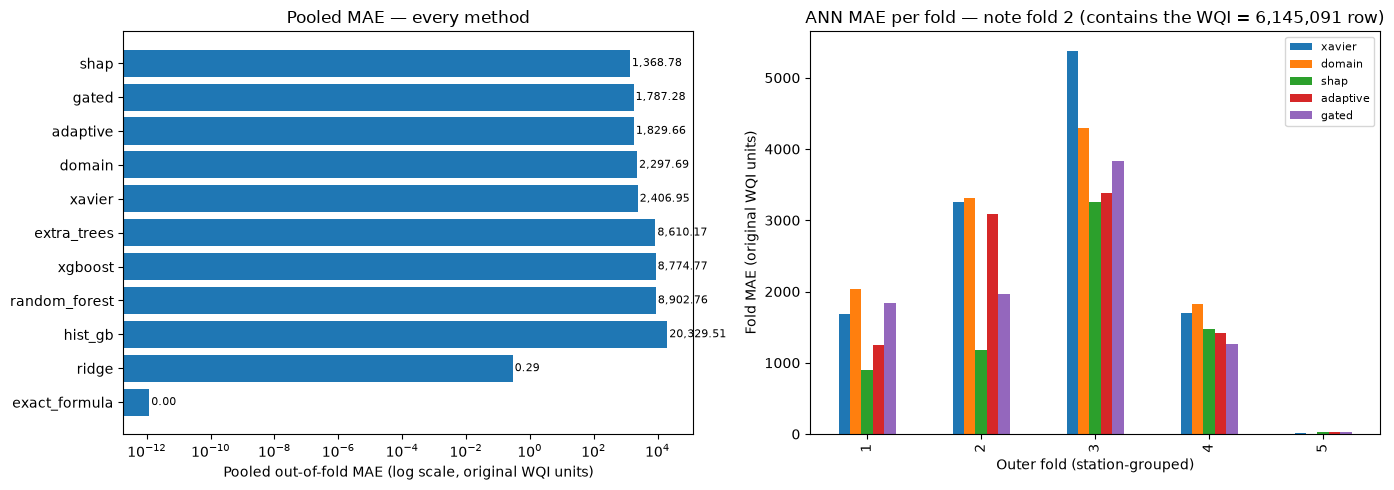

In [11]:
# Plots — pooled MAE (log scale: MAE spans 0.29 to ~20,000) and per-fold ANN MAE
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
order = pooled.set_index("method").loc[
    ["shap", "gated", "adaptive", "domain", "xavier", "extra_trees", "xgboost",
     "random_forest", "hist_gb", "ridge", "exact_formula"]]
ax.barh(order.index, order["mae"])
ax.set_xscale("log")
ax.set_xlabel("Pooled out-of-fold MAE (log scale, original WQI units)")
ax.set_title("Pooled MAE — every method")
for i, v in enumerate(order["mae"]):
    ax.text(v * 1.15, i, f"{v:,.2f}", va="center", fontsize=8)
ax.invert_yaxis()

ax = axes[1]
ann_fold = per_fold[per_fold["method"].isin(ANN_METHODS)]
pivot = ann_fold.pivot(index="fold", columns="method", values="mae")
pivot = pivot[["xavier", "domain", "shap", "adaptive", "gated"]]
pivot.plot(kind="bar", ax=ax)
ax.set_xlabel("Outer fold (station-grouped)")
ax.set_ylabel("Fold MAE (original WQI units)")
ax.set_title("ANN MAE per fold — note fold 2 (contains the WQI = 6,145,091 row)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "notebook" / "pooled_and_per_fold_mae.png", dpi=150)
plt.show()


## 10. What to say in the viva

- **Q3/Q4:** WQI is a linear function of the inputs (fixed standards/ideals/weights), so the ANN reconstructs a known formula. Exact formula ~0 error, Ridge MAE ≈ 0.3 — the ANNs are far behind, and that is the result.
- **Q7:** Novelty is Adaptive Domain-Aware initialisation ($A_i = 0.8 S_i + 0.2 D_i$) plus trainable gating. Station-grouped CV is design, not novelty. The base paper is binary potability classification on a different dataset — it has no D, A, gates, WQI regression, or grouped CV.
- **Q17/Q18:** Row-scaling + Frobenius restoration for the non-gated methods; exp gates (positive, unbounded, $g_i^{(0)} = \sqrt{A_i/\bar A}$) for the gated variant — **not** sigmoid, whatever the diagrams show.
- **Q22:** S is unstable across folds because 3 extreme rows dominate mean |TreeSHAP| — say so before the examiner finds it.
- **Q25/Q26:** Report this notebook's pooled MAE and station tests (above). The Domain-vs-SHAP Wilcoxon and CI were missing (truncated) in the source document — this run fills them in.
- **Base paper (reference only):** Al Bataineh, Vamsi & Smith, IEEE JSTARS Vol. 19, 2026, DOI 10.1109/JSTARS.2026.3654017. Never quote its 86.9% accuracy or its features as this project's results.